<a href="https://colab.research.google.com/github/olonok69/SSL_pathology_demo/blob/main/notebooks/00_setup_and_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 · Setup and data

**Goal.** Put a fixed, public set of H&E tiles on disk so every later notebook sees the same images.

**What you will see.** Class counts, a grid of tiles, and the augmentations BYOL and DINO use next to an H&E stain jitter.

**Runtime.** About 10 minutes in fast mode, most of it the PathMNIST download (224 px, CC BY 4.0). A second run reads the index CSV and skips the subset draw. Full mode is 50k / 7k tiles and is where NCT-CRC and PatchCamelyon belong.

**Talking point.** Slides 3–4: labels in pathology are expensive, so the tiles have to be chosen once and then left alone.


In [1]:
from pathlib import Path
repo = Path("/content/SSL_pathology_demo")
if not (repo / "pyproject.toml").exists():
    !git clone --depth 1 https://github.com/olonok69/SSL_pathology_demo.git /content/SSL_pathology_demo
%cd /content/SSL_pathology_demo

Cloning into '/content/SSL_pathology_demo'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 32 (delta 0), reused 30 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 55.86 KiB | 11.17 MiB/s, done.
/content/SSL_pathology_demo


In [2]:
MODE = "fast"  # "fast" or "full"

import os
import sys
from pathlib import Path

def _find_repo() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "ssl_demo").is_dir():
            return candidate
    raise FileNotFoundError(
        "Launch this notebook from the ssl-pathology-demo repository "
        "(the folder that contains pyproject.toml)."
    )

REPO = _find_repo()
os.chdir(REPO)
src = str(REPO / "src")
if src not in sys.path:
    sys.path.insert(0, src)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    import subprocess
    # pyproject.toml does not pin torch, so a Colab CUDA wheel stays installed.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)])

from ssl_demo.config import SEED, cache_root

CACHE = cache_root()
print(f"MODE={MODE}  SEED={SEED}")
print(f"cache: {CACHE}")


Mounted at /content/drive
MODE=fast  SEED=42
cache: /content/drive/MyDrive/ssl-demo


## The tiles

Fast mode uses **PathMNIST**, the MedMNIST copy of Kather's colorectal tiles. The test split is CRC-VAL-HE-7K: different patients from the train set. That is the same rule as "never split one animal across train and test".

Nine classes. Tumour is colorectal adenocarcinoma epithelium (id 8). Background (id 1) stays in this grid. The anomaly notebook drops it, because empty glass is not a tumour.

Set `INCLUDE_PCAM = True` only if you want Task B. That download is several GB. `NCT_ROOT` points at an already extracted Zenodo 1214456 folder; this notebook does not fetch the 11 GB archive.


In [8]:
from ssl_demo.data import (
    CLASS_NAMES,
    TUMOUR_ID,
    augmentation_previews,
    class_balance,
    find_nct_directory,
    per_class_positions,
    prepare_nct,
    prepare_pathmnist,
    prepare_pcam,
)

INCLUDE_PCAM = True
NCT_ROOT =  "/content/drive/MyDrive/ssl-demo/data/nct" # /content/drive/MyDrive/data

sources = prepare_pathmnist(mode=MODE, cache=CACHE, seed=SEED, size=224, download=True)
for split, source in sources.items():
    print(f"{split}: {len(source.indices)} tiles -> {source.index_csv}")
    print(class_balance(source.subset_labels(), source.class_names).to_string(index=False))
    print()


train: 10000 tiles -> /content/drive/MyDrive/ssl-demo/indices/pathmnist_train_fast.csv
 id                                class    n
  0                              adipose 1041
  1                           background 1057
  2                               debris 1151
  3                          lymphocytes 1156
  4                                mucus  889
  5                        smooth muscle 1354
  6                  normal colon mucosa  876
  7             cancer-associated stroma 1044
  8 colorectal adenocarcinoma epithelium 1432

test: 2000 tiles -> /content/drive/MyDrive/ssl-demo/indices/pathmnist_test_fast.csv
 id                                class   n
  0                              adipose 373
  1                           background 236
  2                               debris  94
  3                          lymphocytes 177
  4                                mucus 288
  5                        smooth muscle 165
  6                  normal colon mucosa 206
  7     

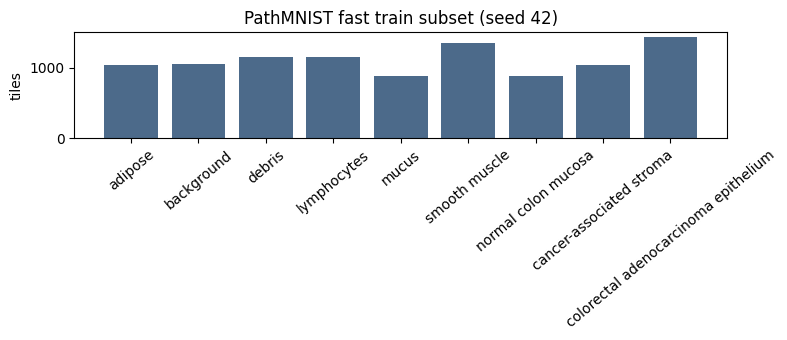

In [4]:
import matplotlib.pyplot as plt

train = sources["train"]
balance = class_balance(train.subset_labels(), train.class_names)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(balance["class"], balance["n"], color="#4c6a8a")
ax.set_ylabel("tiles")
ax.set_title(f"PathMNIST {MODE} train subset (seed {SEED})")
ax.tick_params(axis="x", labelrotation=40)
fig.tight_layout()
plt.show()


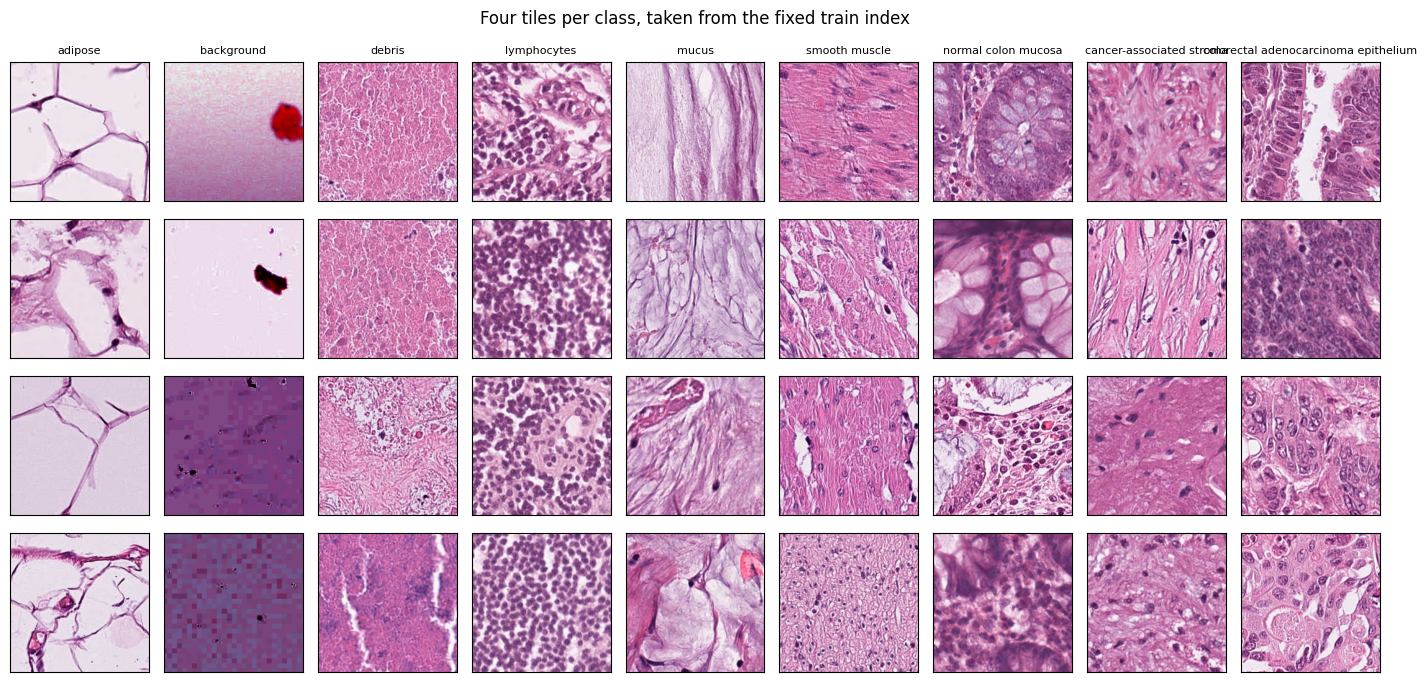

In [5]:
positions = per_class_positions(train.subset_labels(), per_class=4, seed=SEED)
fig, axes = plt.subplots(4, len(CLASS_NAMES), figsize=(14, 7))
for class_id, name in enumerate(CLASS_NAMES):
    chosen = positions.get(class_id, [])
    for row in range(4):
        axes[row, class_id].set_xticks([])
        axes[row, class_id].set_yticks([])
        if row >= len(chosen):
            axes[row, class_id].axis("off")
            continue
        source_index = int(train.indices[int(chosen[row])])
        axes[row, class_id].imshow(train.image(source_index))
        if row == 0:
            axes[row, class_id].set_title(name, fontsize=8)
fig.suptitle("Four tiles per class, taken from the fixed train index")
fig.tight_layout()
plt.show()


## Why ImageNet colour jitter is the wrong knob for H&E

Haematoxylin stains nuclei blue-purple. Eosin stains cytoplasm and stroma pink. Those are dye concentrations, not the colours of a photograph.

ImageNet colour jitter treats the three channels as natural-image RGB. Pushed hard, it paints tissue green or orange, off the stain manifold the later models will see in the lab. Stain jitter converts the tile to HED space and scales the haematoxylin and eosin channels, which is closer to scanner and lab variation.

The crop, blur and solarize panels are the other views BYOL and DINO use. They are previews here, not a training run.


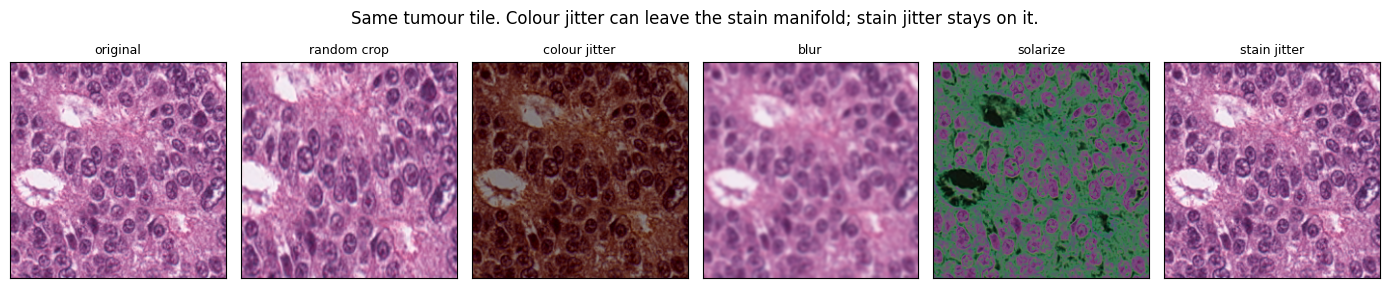

In [6]:
import numpy as np

tumour_rows = np.flatnonzero(train.subset_labels() == TUMOUR_ID)
example_row = int(tumour_rows[0]) if len(tumour_rows) else 0
example = train.image(int(train.indices[example_row]))
previews = {"original": example, **augmentation_previews(example, seed=SEED)}
fig, axes = plt.subplots(1, len(previews), figsize=(14, 3))
for ax, (name, image) in zip(axes, previews.items()):
    ax.imshow(image)
    ax.set_title(name.replace("_", " "), fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Same tumour tile. Colour jitter can leave the stain manifold; stain jitter stays on it.")
fig.tight_layout()
plt.show()


In [9]:
from pathlib import Path
import subprocess
zips = Path("/content/drive/MyDrive/ssl-demo/data/nct")
zips.mkdir(parents=True, exist_ok=True)
extracted = Path("/content/nct")
extracted.mkdir(parents=True, exist_ok=True)
files = {
    "CRC-VAL-HE-7K.zip": "https://zenodo.org/api/records/1214456/files/CRC-VAL-HE-7K.zip/content",
    "NCT-CRC-HE-100K.zip": "https://zenodo.org/api/records/1214456/files/NCT-CRC-HE-100K.zip/content",
}
for name, url in files.items():
    dest = zips / name
    subprocess.check_call(["wget", "-c", "-O", str(dest), url])
    subprocess.check_call(["unzip", "-q", "-n", str(dest), "-d", str(extracted)])
for split, folder in (("train", "NCT-CRC-HE-100K"), ("test", "CRC-VAL-HE-7K")):
    path = extracted / folder
    print(split, path, "TUM" , (path / "TUM").is_dir(), "NORM", (path / "NORM").is_dir())

train /content/nct/NCT-CRC-HE-100K TUM True NORM True
test /content/nct/CRC-VAL-HE-7K TUM True NORM True


In [11]:
NCT_ROOT = "/content/nct"
INCLUDE_PCAM = False

In [12]:
if INCLUDE_PCAM:
    pcam = prepare_pcam(mode=MODE, cache=CACHE, seed=SEED, download=True)
    for split, source in pcam.items():
        print(f"pcam {split}: {len(source.indices)} tiles -> {source.index_csv}")
else:
    print("Task B (PatchCamelyon) is off. Set INCLUDE_PCAM = True to download it.")

if NCT_ROOT:
    nct_root = Path(NCT_ROOT)
    print("NCT train folder:", find_nct_directory(nct_root, "train"))
    print("NCT test folder:", find_nct_directory(nct_root, "test"))
    nct = prepare_nct(nct_root, mode=MODE, cache=CACHE, seed=SEED)
    for split, source in nct.items():
        print(f"nct {split}: {len(source.indices)} tiles -> {source.index_csv}")
else:
    print("NCT-CRC folder not set. Fast mode stays on PathMNIST, which is the same nine classes.")


Task B (PatchCamelyon) is off. Set INCLUDE_PCAM = True to download it.
NCT train folder: /content/nct/NCT-CRC-HE-100K
NCT test folder: /content/nct/CRC-VAL-HE-7K
nct train: 10000 tiles -> /content/drive/MyDrive/ssl-demo/indices/nct_train_fast.csv
nct test: 2000 tiles -> /content/drive/MyDrive/ssl-demo/indices/nct_test_fast.csv


## What we learned

- The fast subset is fixed by seed 42 and an index CSV under the cache. Later notebooks load that file instead of drawing a new subset.
- PathMNIST's test split is the patient-disjoint CRC-VAL set, which is the split we want for a probe and for anomaly scores.
- ImageNet colour jitter is a blunt tool on H&E. Stain jitter scales dye concentrations and is the histology-shaped alternative.

Index CSVs were printed above (`cache/indices/pathmnist_{train,test}_<mode>.csv`).
